In [276]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,f1_score, classification_report
from sklearn.preprocessing import OrdinalEncoder,LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

In [277]:
df=pd.read_csv("/content/telecom_customer_churn.csv")
df.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [278]:
df.shape

(7043, 38)

In [279]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   objec

In [280]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
Married,0
Number of Dependents,0
City,0
Zip Code,0
Latitude,0
Longitude,0
Number of Referrals,0


In [281]:
nums=df.select_dtypes(include=["int64",'float64'])
catr=df.select_dtypes(include=['object'])


In [282]:
df.describe()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,6361.000000,5517.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,1.951867,32.386767,25.420517,26.189958,63.596131,2280.381264,1.962182,6.860713,749.099262,3034.379056
std,16.750352,0.962802,1856.767505,2.468929,2.154425,3.001199,24.542061,14.200374,19.586585,31.204743,2266.220462,7.902614,25.104978,846.660055,2865.204542
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,0.000000,1.000000,1.010000,2.000000,-10.000000,18.800000,0.000000,0.000000,0.000000,21.360000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,0.000000,9.000000,13.050000,13.000000,30.400000,400.150000,0.000000,0.000000,70.545000,605.610000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,0.000000,29.000000,25.690000,21.000000,70.050000,1394.550000,0.000000,0.000000,401.440000,2108.640000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,3.000000,55.000000,37.680000,30.000000,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000


In [283]:
df['Monthly Charge'].describe()

,Monthly Charge
count,7043.000000
mean,63.596131
std,31.204743
min,-10.000000
25%,30.400000
50%,70.050000
75%,89.750000
max,118.750000


In [284]:
(df['Monthly Charge'] < 0).sum()

np.int64(120)

In [285]:
med = df.loc[df['Monthly Charge'] > 0, 'Monthly Charge'].median()
df.loc[df['Monthly Charge'] < 0, 'Monthly Charge'] = med

In [286]:
(df['Monthly Charge'] < 0).sum()

np.int64(0)

In [287]:
df.describe()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,6361.000000,5517.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,1.951867,32.386767,25.420517,26.189958,64.887058,2280.381264,1.962182,6.860713,749.099262,3034.379056
std,16.750352,0.962802,1856.767505,2.468929,2.154425,3.001199,24.542061,14.200374,19.586585,29.858752,2266.220462,7.902614,25.104978,846.660055,2865.204542
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,0.000000,1.000000,1.010000,2.000000,18.250000,18.800000,0.000000,0.000000,0.000000,21.360000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,0.000000,9.000000,13.050000,13.000000,36.475000,400.150000,0.000000,0.000000,70.545000,605.610000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,0.000000,29.000000,25.690000,21.000000,70.350000,1394.550000,0.000000,0.000000,401.440000,2108.640000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,3.000000,55.000000,37.680000,30.000000,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000


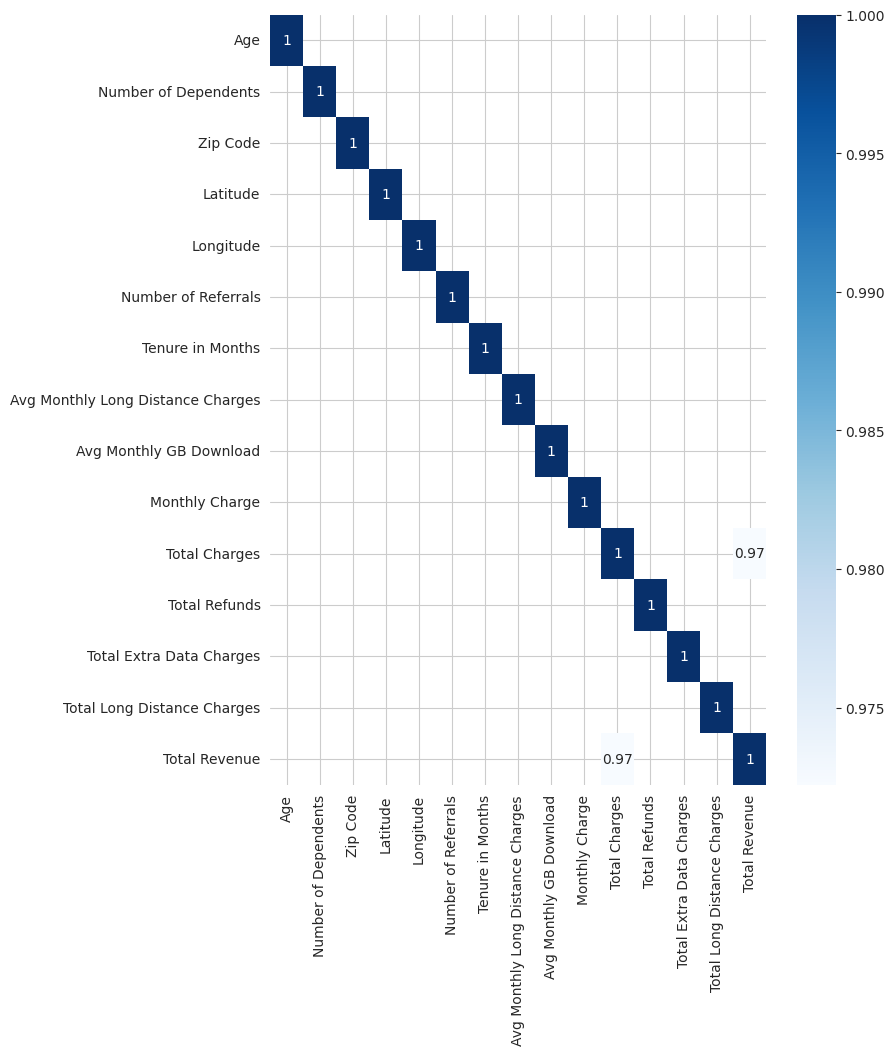

In [288]:
plt.figure(figsize=(8,10))
sns.heatmap(nums.corr(),annot=True,cmap='Blues',mask=nums.corr()<0.90)
plt.show()

<Axes: xlabel='Tenure in Months', ylabel='Total Revenue'>

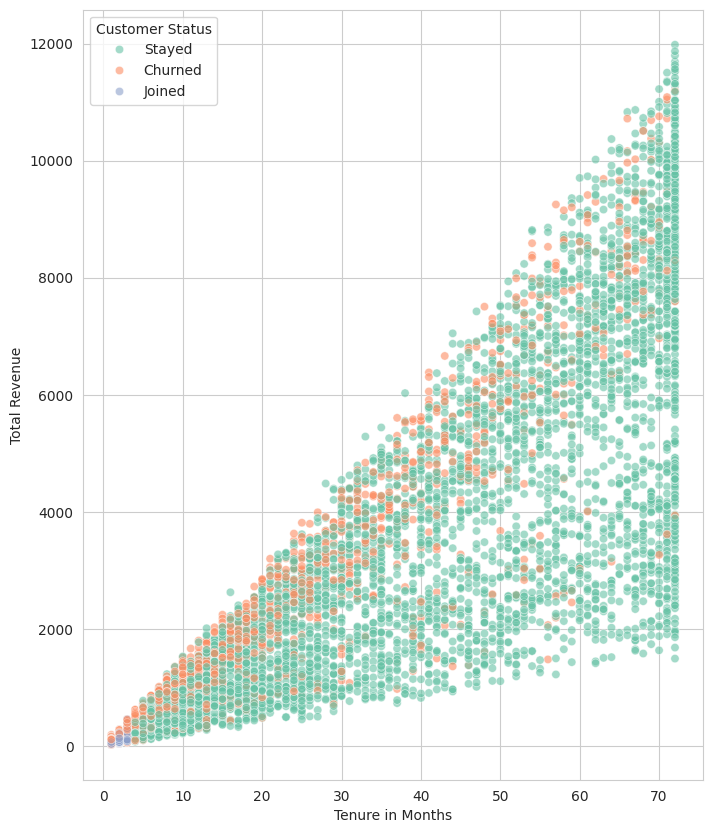

In [289]:
plt.figure(figsize=(8,10))
sns.set_style("whitegrid")
sns.scatterplot(
    data=df,
    x='Tenure in Months',
    y='Total Revenue',
    hue='Customer Status',
    alpha=0.6,
    palette='Set2')

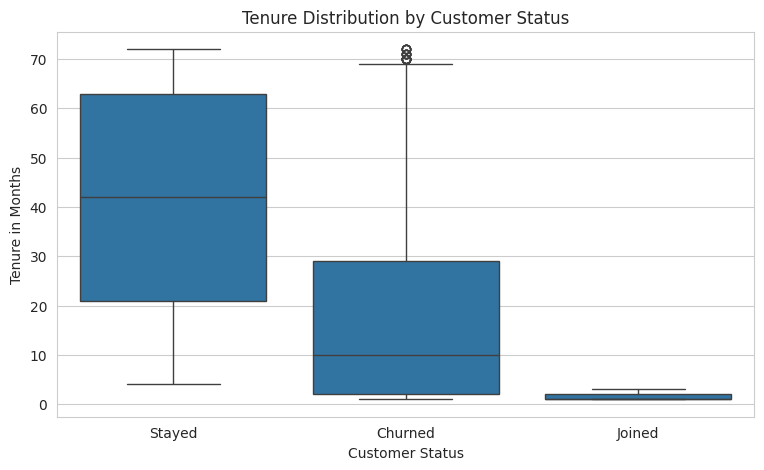

In [290]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x=catr['Customer Status'],
    y='Tenure in Months'
)

plt.title('Tenure Distribution by Customer Status')
plt.show()

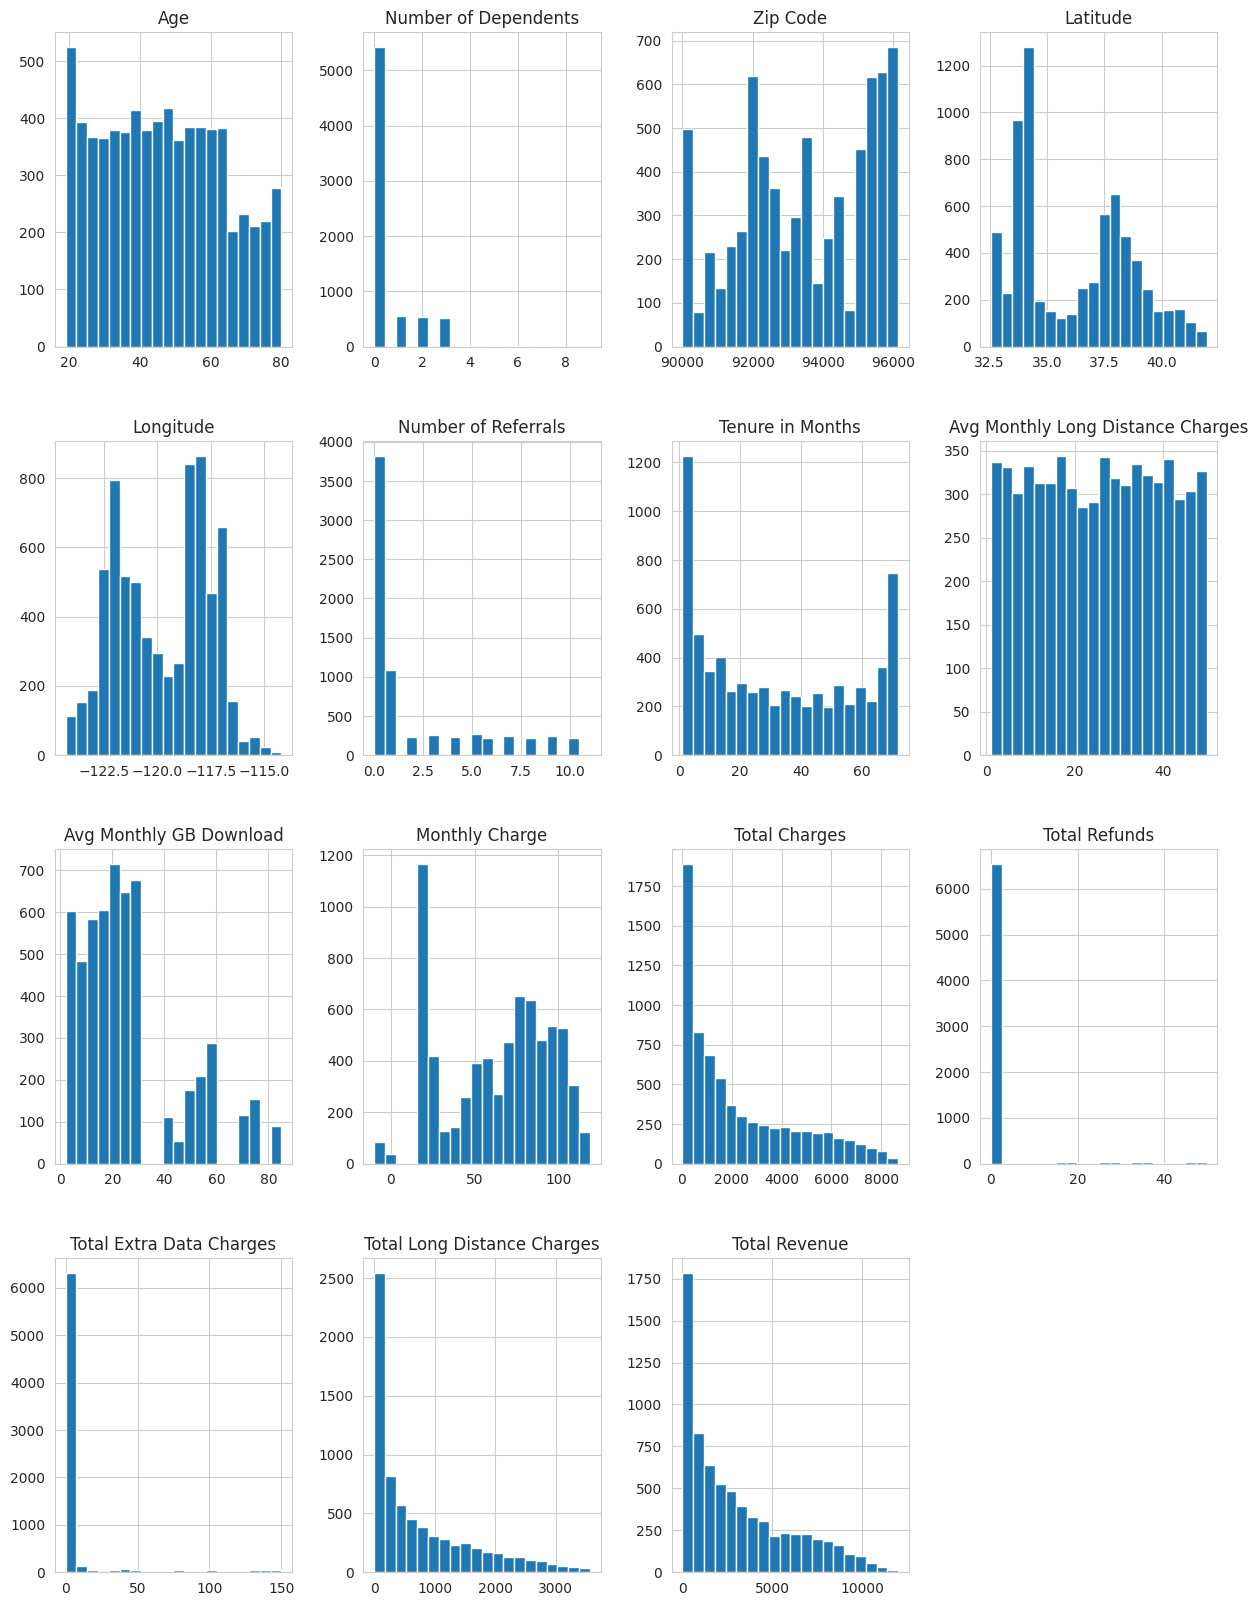

In [291]:
nums.hist(figsize=(15, 20), bins=20)
plt.show()

In [292]:
df['Customer Status'].value_counts()

,count
Customer Status,
Stayed,4720
Churned,1869
Joined,454


In [293]:
df['goll'] = catr['Customer Status'].apply(lambda x: 0 if x == 'Stayed' else (1 if x == 'Churned' else 2))
df['goll'].value_counts()

,count
goll,
0,4720
1,1869
2,454


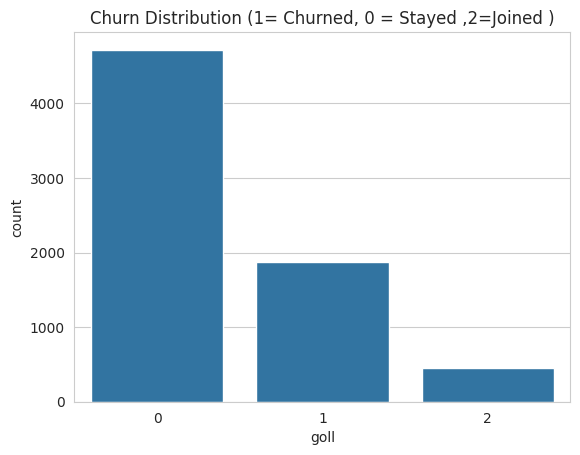

In [294]:
sns.countplot(x='goll', data=df)
plt.title('Churn Distribution (1= Churned, 0 = Stayed ,2=Joined )')
plt.show()

In [295]:
df.drop(['Churn Reason','Churn Category','Customer ID','Customer Status','Total Charges','Total Refunds','Zip Code','City','Total Revenue'],axis=1,inplace=True)

In [296]:
catr.columns.tolist()

['Customer ID',
 'Gender',
 'Married',
 'City',
 'Offer',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Internet Type',
 'Online Security',
 'Online Backup',
 'Device Protection Plan',
 'Premium Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Streaming Music',
 'Unlimited Data',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Customer Status',
 'Churn Category',
 'Churn Reason']

In [297]:
non= ['Internet Type', 'Online Security', 'Online Backup',
                'Device Protection Plan', 'Premium Tech Support',
                'Streaming TV', 'Streaming Movies', 'Streaming Music',
                'Unlimited Data', 'Multiple Lines', 'Offer']

In [298]:
df[non]=df[non].fillna('None')

In [299]:
df.isnull().sum()

,0
Gender,0
Age,0
Married,0
Number of Dependents,0
Latitude,0
Longitude,0
Number of Referrals,0
Tenure in Months,0
Offer,0
Phone Service,0


In [300]:
ze=['Avg Monthly Long Distance Charges','Avg Monthly GB Download']
df[ze]=df[ze].fillna(0)

In [301]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   object 
 1   Age                                7043 non-null   int64  
 2   Married                            7043 non-null   object 
 3   Number of Dependents               7043 non-null   int64  
 4   Latitude                           7043 non-null   float64
 5   Longitude                          7043 non-null   float64
 6   Number of Referrals                7043 non-null   int64  
 7   Tenure in Months                   7043 non-null   int64  
 8   Offer                              7043 non-null   object 
 9   Phone Service                      7043 non-null   object 
 10  Avg Monthly Long Distance Charges  7043 non-null   float64
 11  Multiple Lines                     7043 non-null   objec

In [302]:
df.isnull().sum()

,0
Gender,0
Age,0
Married,0
Number of Dependents,0
Latitude,0
Longitude,0
Number of Referrals,0
Tenure in Months,0
Offer,0
Phone Service,0


In [303]:
x=df.drop(["goll"] , axis=1)
y=df["goll"]

In [304]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [305]:
from sklearn.impute import SimpleImputer

nume = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [306]:
cate=Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])

In [307]:
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = x_train.select_dtypes(include=['object']).columns.tolist()

proces = ColumnTransformer([('num', nume, num_cols),
                            ('cat', cate, cat_cols)])

In [308]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

In [309]:
model_Pipeline = Pipeline([

     ('process', proces), ('model', RandomForestClassifier( random_state=42,
        class_weight='balanced'))])
model_Pipeline.fit(x_train, y_train)


Pipeline(steps=[('process',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Number of Dependents',
                                                   'Latitude', 'Longitude',
                                                   'Number of Referrals',
                                                   'Tenure in Months',
                                                   'Avg Monthly Long Distance '
                                                   'Charges',
                                                   'Avg Monthly GB Download',
                                                   'Monthly Charge',
                                                   'Total Extra Data Charges',
                                                   'Total Lo...
                                                  ['Gender', 'Married', 'Offer',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Internet Type',
                                                   'Online Security',
                                                   'Online Backup',
                                                   'Device Protection Plan',
                                                   'Premium Tech Support',
                                                   'Streaming TV',
                                                   'Streaming Movies',
                                                   'Streaming Music',
                                                   'Unlimited Data', 'Contract',
                                                   'Paperless Billing',
                                                   'Payment Method'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [310]:
y_pred = model_Pipeline.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.96      0.91       944
           1       0.71      0.59      0.64       374
           2       0.73      0.45      0.56        91

    accuracy                           0.83      1409
   macro avg       0.77      0.67      0.70      1409
weighted avg       0.82      0.83      0.82      1409



In [311]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_pipe = Pipeline([
    ('process', proces),
    ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
])

hgb_pipe.fit(x_train, y_train)
y_pred_hgb = hgb_pipe.predict(x_test)
print(classification_report(y_test, y_pred_hgb))

              precision    recall  f1-score   support

           0       0.90      0.90      0.90       944
           1       0.69      0.66      0.67       374
           2       0.70      0.74      0.72        91

    accuracy                           0.83      1409
   macro avg       0.76      0.77      0.76      1409
weighted avg       0.83      0.83      0.83      1409



In [312]:
print("RF  macro F1:", f1_score(y_test, model_Pipeline.predict(x_test), average='macro'))
print("HGB macro F1:", f1_score(y_test, y_pred_hgb, average='macro'))

RF  macro F1: 0.703174818195815
HGB macro F1: 0.7639366149329776


In [313]:
import joblib
joblib.dump(hgb_pipe, 'churn_hgb_model.pkl')

['churn_hgb_model.pkl']